In [ ]:
#working without preprocessing

In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Reload the completely unmodified raw dataset
df_raw = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Split features and target as they are in the raw file (retaining all string formats, missing values, and IDs)
X_raw = df_raw.drop(columns=['Churn'])
y_raw = df_raw['Churn']

# --- Model 1: Logistic Regression ---
print("--- Attempting to train Logistic Regression on raw data ---")
try:
    lr_model = LogisticRegression(max_iter=1000, random_state=42)
    lr_model.fit(X_raw, y_raw)
    print("Logistic Regression fitted successfully!")
except Exception as e:
    print(f"[Logistic Regression FAILURE]: {type(e).__name__} - {e}")

# --- Model 2: Random Forest Classifier ---
print("\n--- Attempting to train Random Forest Classifier on raw data ---")
try:
    rf_model = RandomForestClassifier(random_state=42)
    rf_model.fit(X_raw, y_raw)
    print("Random Forest fitted successfully!")
except Exception as e:
    print(f"[Random Forest FAILURE]: {type(e).__name__} - {e}")

--- Attempting to train Logistic Regression on raw data ---
[Logistic Regression FAILURE]: ValueError - could not convert string to float: '7590-VHVEG'

--- Attempting to train Random Forest Classifier on raw data ---
[Random Forest FAILURE]: ValueError - could not convert string to float: '7590-VHVEG'


In [ ]:
#working with models that would not need preprocessing

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.5 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import numpy as np

# 1. Reload raw data
df_raw = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# We will only drop 'customerID' because it is a unique identifier, but keep all other raw string columns exactly as they are!
X = df_raw.drop(columns=['Churn', 'customerID'])
y = df_raw['Churn']

# Identify categorical columns natively
cat_features = list(X.select_dtypes(include=['object']).columns)
print("Categorical features detected natively:", cat_features)

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Train CatBoost model
# We pass the list of categorical feature names directly into CatBoost!
model = CatBoostClassifier(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    cat_features=cat_features,
    verbose=10,
    random_state=42
)

print("\nTraining CatBoost directly on raw columns...")
model.fit(X_train, y_train)

# 3. Evaluate
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"\nCatBoost Accuracy on Raw Unprocessed Data: {acc:.4f}")

Categorical features detected natively: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']

Training CatBoost directly on raw columns...
0:	learn: 0.6564520	total: 55.6ms	remaining: 5.51s
10:	learn: 0.4859328	total: 107ms	remaining: 866ms
20:	learn: 0.4380928	total: 160ms	remaining: 603ms
30:	learn: 0.4213441	total: 207ms	remaining: 461ms
40:	learn: 0.4128584	total: 254ms	remaining: 365ms
50:	learn: 0.4058292	total: 308ms	remaining: 296ms
60:	learn: 0.4019508	total: 358ms	remaining: 229ms
70:	learn: 0.3992996	total: 410ms	remaining: 167ms
80:	learn: 0.3964828	total: 457ms	remaining: 107ms
90:	learn: 0.3945059	total: 508ms	remaining: 50.3ms
99:	learn: 0.3920353	total: 562ms	remaining: 0us

CatBoost Accuracy on Raw Unprocessed Data: 0.8126


In [ ]:
# 4. Generate comparison tables using CatBoost's predictions
import numpy as np
import pandas as pd

sample_indices = np.random.RandomState(42).choice(len(y_test), 15, replace=False)

sample_actuals = y_test.iloc[sample_indices].values
sample_preds = y_pred[sample_indices]

table_catboost = pd.DataFrame({
    'Sample ID': np.arange(1, 16),
    'Actual Churn': sample_actuals,
    'CatBoost Prediction': sample_preds,
    'Prediction Correct': [act == pred for act, pred in zip(sample_actuals, sample_preds)]
})

print("--- TABLE: CatBoost Sample Predictions on Unpreprocessed Data ---")
display(table_catboost)

--- TABLE: CatBoost Sample Predictions on Unpreprocessed Data ---


,Sample ID,Actual Churn,CatBoost Prediction,Prediction Correct
0,1,Yes,No,False
1,2,No,No,True
2,3,No,No,True
3,4,No,No,True
4,5,No,No,True
5,6,No,No,True
6,7,Yes,No,False
7,8,No,No,True
8,9,No,No,True
9,10,No,No,True


### Thorough Data Preprocessing and Train-Test Split

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# 1. Load the raw dataset
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# 2. Drop the customerID column as it is only a unique identifier
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# 3. Clean 'TotalCharges' column and apply Imputation
# TotalCharges has some empty space values (" ") which prevent it from being loaded as numeric
df['TotalCharges'] = df['TotalCharges'].replace(" ", np.nan)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

# Use SimpleImputer to impute missing values (using the median strategy)
imputer = SimpleImputer(strategy='median')
df[['TotalCharges']] = imputer.fit_transform(df[['TotalCharges']])

# 4. Encode the target variable 'Churn'
# Convert 'Yes'/'No' in Churn to 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 5. One-Hot Encode all other categorical variables
# Identify categorical columns to encode
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print("Categorical columns being One-Hot Encoded:", categorical_cols)

# Apply pd.get_dummies to convert categorical features to binary columns
df_processed = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Display the shape and preview of the fully processed DataFrame
print(f"\nProcessed Dataset Shape: {df_processed.shape}")
display(df_processed.head())

Categorical columns being One-Hot Encoded: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Processed Dataset Shape: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


In [ ]:
# 6. Split features and target
X_clean = df_processed.drop(columns=['Churn'])
y_clean = df_processed['Churn']

# 7. Split into 80% Training and 20% Testing
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42,
    stratify=y_clean
)

print(f"Training set shape: {X_train_clean.shape}")
print(f"Testing set shape: {X_test_clean.shape}")


Training set shape: (5634, 30)
Testing set shape: (1409, 30)


### Comparison: Before vs. After One-Hot Encoding

In [ ]:
# Compare shapes
print(f"Original dataset columns count (excluding customerID): {df.shape[1]}")
print(f"Processed dataset columns count (after One-Hot Encoding): {df_processed.shape[1]}\n")

# Identify the dummy columns created
original_cols = set(df.columns) - set(categorical_cols)
new_cols = set(df_processed.columns) - original_cols
print(f"Created {len(new_cols)} dummy columns from {len(categorical_cols)} categorical features:")
print(sorted(list(new_cols)))

# Display the head of the processed dataset
print("\nHead of the preprocessed dataset:")
display(df_processed.head())

Original dataset columns count (excluding customerID): 20
Processed dataset columns count (after One-Hot Encoding): 31

Created 26 dummy columns from 15 categorical features:
['Contract_One year', 'Contract_Two year', 'Dependents_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'PaperlessBilling_Yes', 'Partner_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'PhoneService_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'gender_Male']

Head of the preprocessed dataset:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


### Training and Evaluating an XGBoost Classifier on Preprocessed Data

In [ ]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Initialize the XGBoost classifier
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)

# Train the model using the cleaned training sets
xgb_model.fit(X_train_clean, y_train_clean)

# Predict on the cleaned testing set
y_pred_clean = xgb_model.predict(X_test_clean)

# Calculate accuracy
accuracy = accuracy_score(y_test_clean, y_pred_clean)
print(f"XGBoost Accuracy on Preprocessed Data: {accuracy:.4f}\n")

# Output a detailed classification report
print("Classification Report:")
print(classification_report(y_test_clean, y_pred_clean))

XGBoost Accuracy on Preprocessed Data: 0.8020

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.54      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



### Training and Evaluating a CatBoost Classifier on Preprocessed Data

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize the CatBoost Classifier with automatic class balancing
catboost_model_clean = CatBoostClassifier(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    random_state=42,
    verbose=10
)

# Train on the preprocessed training set
catboost_model_clean.fit(X_train_clean, y_train_clean)

# Predict on the preprocessed testing set
y_pred_cat_clean = catboost_model_clean.predict(X_test_clean)

# Calculate accuracy
cat_accuracy = accuracy_score(y_test_clean, y_pred_cat_clean)
print(f"\nCatBoost Accuracy on Preprocessed Data: {cat_accuracy:.4f}\n")

# Output a detailed classification report
print("Classification Report:")
print(classification_report(y_test_clean, y_pred_cat_clean))

0:	learn: 0.6276326	total: 7.33ms	remaining: 726ms
10:	learn: 0.4394747	total: 79.8ms	remaining: 646ms
20:	learn: 0.4095491	total: 138ms	remaining: 521ms
30:	learn: 0.3958672	total: 207ms	remaining: 461ms
40:	learn: 0.3869452	total: 265ms	remaining: 382ms
50:	learn: 0.3803270	total: 358ms	remaining: 344ms
60:	learn: 0.3747018	total: 412ms	remaining: 264ms
70:	learn: 0.3681023	total: 476ms	remaining: 194ms
80:	learn: 0.3626462	total: 539ms	remaining: 126ms
90:	learn: 0.3568341	total: 590ms	remaining: 58.3ms
99:	learn: 0.3521852	total: 644ms	remaining: 0us

CatBoost Accuracy on Preprocessed Data: 0.7977

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



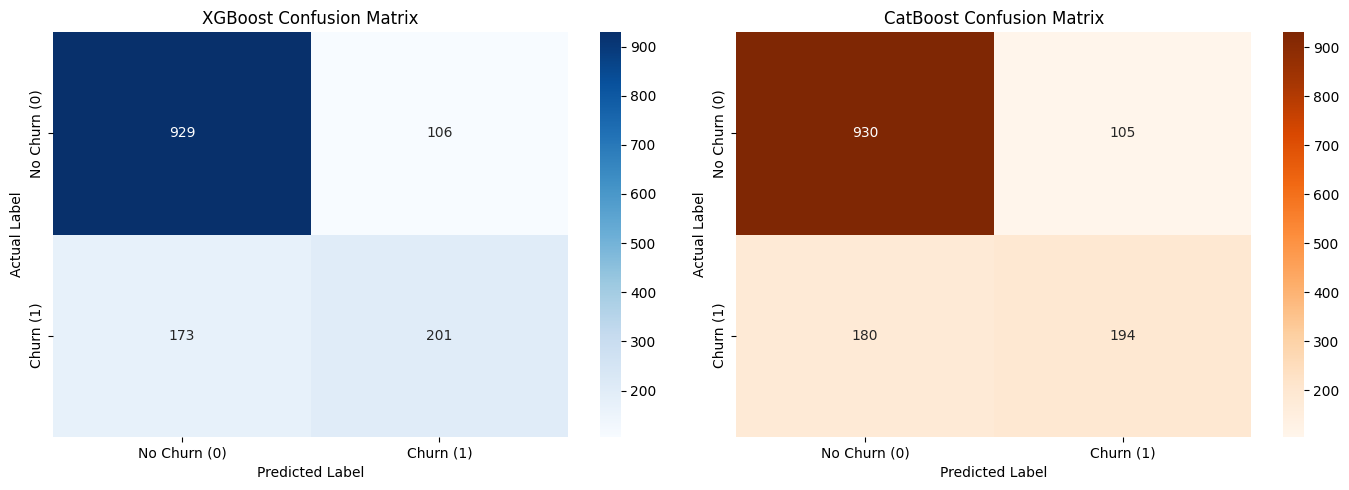

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrices
cm_xgb = confusion_matrix(y_test_clean, y_pred_clean)
cm_cat = confusion_matrix(y_test_clean, y_pred_cat_clean)

# Set up the plotting environment
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot XGBoost Confusion Matrix
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Churn (0)', 'Churn (1)'],
            yticklabels=['No Churn (0)', 'Churn (1)'])
axes[0].set_title('XGBoost Confusion Matrix')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

# Plot CatBoost Confusion Matrix
sns.heatmap(cm_cat, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['No Churn (0)', 'Churn (1)'],
            yticklabels=['No Churn (0)', 'Churn (1)'])
axes[1].set_title('CatBoost Confusion Matrix')
axes[1].set_ylabel('Actual Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

Balanced CatBoost Accuracy: 0.7459190915542938

Balanced CatBoost Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.51      0.77      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.75      0.76      1409



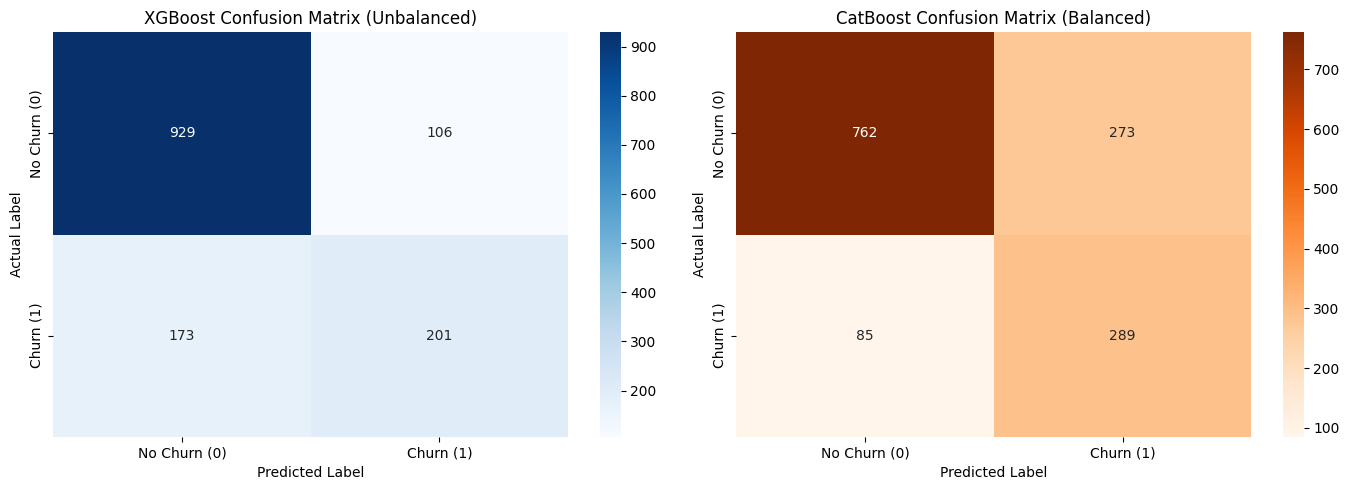

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Retrain the CatBoost Classifier with corrected class weights
catboost_model_balanced = CatBoostClassifier(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    random_state=42,
    verbose=0,
    auto_class_weights='Balanced'
)

catboost_model_balanced.fit(X_train_clean, y_train_clean)

# 2. Get predictions from the newly balanced model
y_pred_cat_balanced = catboost_model_balanced.predict(X_test_clean)

# 3. Print the classification report to see performance changes
print("Balanced CatBoost Accuracy:", accuracy_score(y_test_clean, y_pred_cat_balanced))
print("\nBalanced CatBoost Classification Report:")
print(classification_report(y_test_clean, y_pred_cat_balanced))

# 4. Generate and display updated side-by-side confusion matrices
cm_xgb = confusion_matrix(y_test_clean, y_pred_clean)
cm_cat_bal = confusion_matrix(y_test_clean, y_pred_cat_balanced)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# XGBoost Matrix
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Churn (0)', 'Churn (1)'],
            yticklabels=['No Churn (0)', 'Churn (1)'])
axes[0].set_title('XGBoost Confusion Matrix (Unbalanced)')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

# Balanced CatBoost Matrix
sns.heatmap(cm_cat_bal, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['No Churn (0)', 'Churn (1)'],
            yticklabels=['No Churn (0)', 'Churn (1)'])
axes[1].set_title('CatBoost Confusion Matrix (Balanced)')
axes[1].set_ylabel('Actual Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()